# `rioxarray`

In this lesson we will introduce [`rioxarray`](https://corteva.github.io/rioxarray/stable/), a Python extension for `xarray` to manipulate `xarray.DataArray`s as rasters. 

The name `rioxarray` stands for *raster input/output + xarray*. 

## About the data
The raster files we will use today come from the [US National Agriculture Imagery Program (NAIP)](https://naip-usdaonline.hub.arcgis.com). 
NAIP images are are high-resolution aerial images with four spectral bands: red (R), green (G), blue (B) and near-infrared (NIR). 
The raster's we'll use today are from 2020.

The data used in this lesson was pre-processing from a complete NAIP scene to separate the RGB bands from the NIR band and reduce the spatial extent. 
The data was accessed through [Microsoft's Planetary Computer NAIP data repository](https://planetarycomputer.microsoft.com/dataset/naip#overview).

## Import a TIF file

Let's start by loading the libraries we will use: 

In [14]:
import os

import numpy as np
import matplotlib.pyplot as plt

import geopandas as gpd

import rioxarray as rioxr

There are [multiple ways of opening a TIF file using `xarray` or `rioxarray`](https://corteva.github.io/rioxarray/html/getting_started/getting_started.html). 
Using the `rioxarray.open_rasterio()` function to open the TIF file is a simple way to import the raster file as an `xarray.DataArray` and make sure all our geospatial data gets loaded correctly:

In [15]:
# # Import NIR TIF file
# root = os.path.join('/',
#                   'courses',
#                   'EDS220',
#                   'data',
#                   'rioxarray_lesson_data')


In [16]:
# Import NIR TIF file

fp = os.path.join('data','NAIP_SB','NAIP_SB_nir.tif')
nir = rioxr.open_rasterio(fp)
nir



<xarray.DataArray (band: 1, y: 3208, x: 2419)> Size: 8MB
[7760152 values with dtype=uint8]
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [17]:
# Access attributes directly
print('shape:', nir.shape)
print('Data type:', nir.dtype)

shape: (1, 3208, 2419)
Data type: uint8


In [18]:
nir.plot

## Drop a dimnesion

The raster has an unnecessaty ectra dimension: band.

In [19]:
print('Size of dimensions:', dict(nir.sizes))

Size of dimensions: {'band': 1, 'y': 3208, 'x': 2419}


- `band` has the length1, so it makes the `xarray`

In [20]:
# Original dimensions and coordinates
print(nir.dims, nir.coords,'\n')

# Remove length 1 dimension (band) and its coordinate
nir = nir.squeeze('band', drop=True)
print(nir.dims, nir.coords)

('band', 'y', 'x') Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0 

('y', 'x') Coordinates:
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0


## `rio` accessor  

In [21]:
# Examine raster attributes using the rio accesor

print("Number of bands:", nir.rio.count)
print("Height:", nir.rio.height)
print("Width:", nir.rio.width), '/n'

print("CRS:", nir.rio.crs ),'/n'

print("Spatial bounding box:," )
print(nir.rio.bounds())

Number of bands: 1
Height: 3208
Width: 2419
CRS: EPSG:26911
Spatial bounding box:,
(251218.8, 3811027.2, 252670.19999999998, 3812952.0)


## Multi-band raster

In [22]:
## Import RGBD raster
fp = os.path.join('data','NAIP_SB','NAIP_SB_rgb.tif')
rgb = rioxr.open_rasterio(fp)
rgb

<xarray.DataArray (band: 3, y: 3208, x: 2419)> Size: 23MB
[23280456 values with dtype=uint8]
Coordinates:
  * band         (band) int64 24B 1 2 3
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

Check-in 

Obstain the information: Shape, number of bands, datatype and the CRS. 

In [23]:
# Examine raster attributes using the rio accesor

print("Number of bands:", rgb.rio.count)
print("Shape:", rgb.rio.shape)
print("data type:", rgb.rio.dtypes), '/n'

print("CRS:", rgb.rio.crs ),'/n'

print("Spatial bounding box:," )
print(rgb.rio.bounds())

Number of bands: 3
Shape: (3208, 2419)


AttributeError: 'RasterArray' object has no attribute 'dtypes'

In [24]:
# Plot the three bands as RGB image 
rgb_aspect_ratio= rgb.rio.width/rgb.rio.height #Raster's aspect ratio

rgb.plot.imshow(figsize=(8 * rgb_aspect_ratio,8))

## Clip raster 



<Axes: >

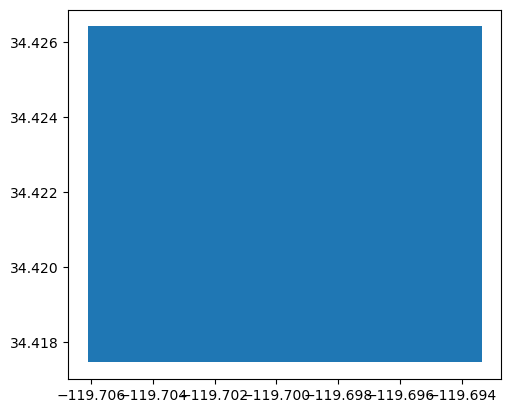

In [25]:
## Import RGBD raster
fp = os.path.join('data','SB_aoi.geojson')
aoi = gpd.read_file(fp)
aoi.plot()

In [26]:
# Examine the CRSs
print('aoi CRS:', aoi.crs) # does not need rio because of object type
print('nir CRS:', nir.rio.crs)
print('rgb CRS:', rgb.rio.crs)

aoi CRS: EPSG:4326
nir CRS: EPSG:26911
rgb CRS: EPSG:26911


In [27]:
# Reproject our AOI to our RGB CRS
aoi = aoi.to_crs(rgb.rio.crs)
assert aoi.crs == rgb.rio.crs

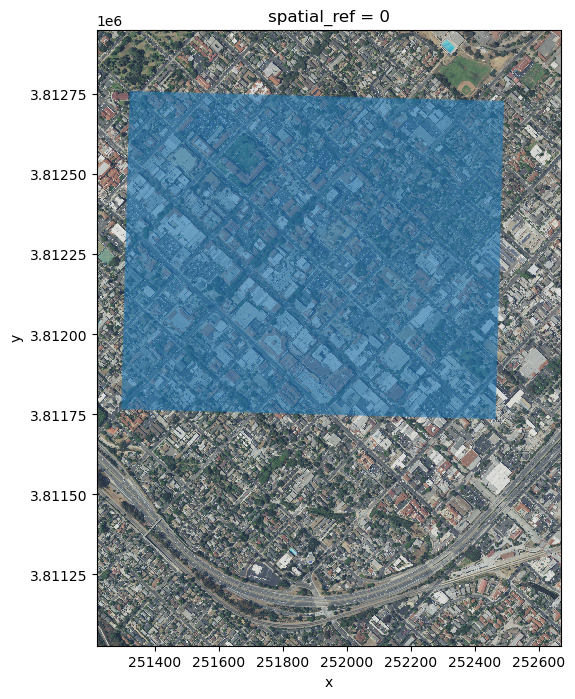

In [28]:
# Plot of RGB raster with AOI overlay
fig, ax = plt.subplots(figsize=(8 * rgb_aspect_ratio, 8))
rgb.plot.imshow(ax=ax)
aoi.plot(ax=ax, alpha=0.6)
plt.show()

In [29]:
aoi.total_bounds

array([ 251294.69376981, 3811735.1717313 ,  252491.02511929,
       3812760.31191696])

In [30]:
# rgb.rio.clip_box(aoi.total_bounds) will not run because it needs 'miny', 'maxx', and 'maxy'
rgb_small = rgb.rio.clip_box(*aoi.total_bounds) # you can also hardcode the output of aoi.total_bounds


In [31]:
nir_small = nir.rio.clip_box(*aoi.total_bounds)

Original shape: (3208, 2419)
Clipped shape: (1710, 1995)


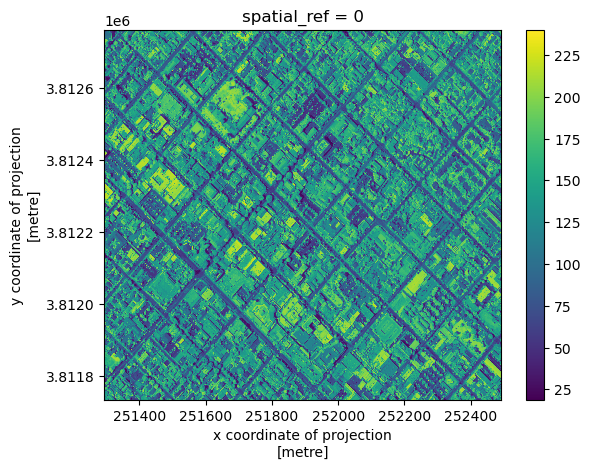

In [32]:
# Examine the clipped data 
print('Original shape:', nir.shape)
print('Clipped shape:', nir_small.shape)

nir_small.plot()

## Raster math 

We will compute the **Normalized Difference Vegitation Index(NDVI)** over our AOI. 

NDVI checks whether an area has live green vegitatio . 

NDVI is always between -1 and 1: values about 0,6 correspons to lush vegitation, water, roofs, pavement, closte to zero or negative; sand, rock, snow, 0.1 and below. Generally above ~0.1 is negative. 

NDVI uses the NIR and red bands:

$$NDVI =(NDIR-Red)/(NIR+Red)

In [33]:
# Select dimnesion by nae and coordinate by label 
red_small = rgb_small.sel(band=1)
red_small

<xarray.DataArray (y: 1710, x: 1995)> Size: 3MB
[3411450 values with dtype=uint8]
Coordinates:
    band         int64 8B 1
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [34]:
ndvi = (nir_small-red_small)/(nir_small+red_small)
ndvi

<xarray.DataArray (y: 1710, x: 1995)> Size: 27MB
array([[3.37500000e+00, 9.25000000e+00, 4.50000000e+01, ...,
        1.18811881e+00, 2.46913580e-02, 1.22448980e-01],
       [           inf, 2.88888889e+00, 9.00000000e+00, ...,
        2.35000000e+02, 6.54205607e-02, 1.87500000e-01],
       [3.23076923e-01, 3.49112426e-01, 3.07692308e-01, ...,
        1.66666667e-01, 5.28571429e+00, 2.40000000e-01],
       ...,
       [1.06779661e+00, 9.76470588e-01, 9.84313725e-01, ...,
        4.22222222e+00, 8.70370370e+00, 1.06926407e+00],
       [9.92156863e-01, 8.06451613e-03, 1.03278689e+00, ...,
        3.69696970e+00, 2.14018692e+00, 2.60919540e+00],
       [6.83783784e+00, 0.00000000e+00, 1.02409639e+00, ...,
        1.95934959e+00, 1.51282051e+00, 1.52287582e+00]])
Coordinates:
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
    band         int64 8B 1

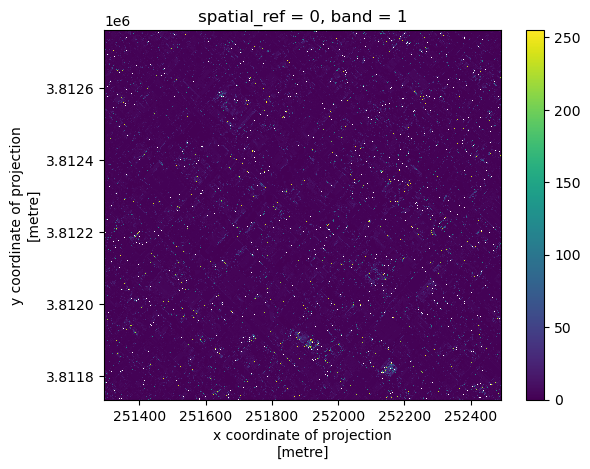

In [35]:
ndvi.plot()

Without plotting it we wouldn't know that there was an issue. 

How can we see that there is not something right:
- the scale bar 
- data type issue: Cannot hold negative numbers and only integers

## Data type issues 

In [38]:
nir_small

<xarray.DataArray (y: 1710, x: 1995)> Size: 3MB
[3411450 values with dtype=uint8]
Coordinates:
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [ ]:
np.uint8(150) + np.uint8(150)
# There was no warning previously of the overflow and was noticable when the data was plotted

/tmp/ipykernel_193048/1890984988.py:1: RuntimeWarning: overflow encountered in scalar add
  np.uint8(150) + np.uint8(150)


44

**Avoid silent failutes! ALWAYS verify your results!** 

In [40]:
#Update data type to int16 to perform NDVI calculations
red16 = red_small.astype('int16')
nir16 = nir_small.astype('int16')

print('Red: Original data type', rgb_small.dtype, '... coverted dtype:', red16.dtype)
print('NIR: Original data type', nir_small.dtype, '... coverted dtype:', nir16.dtype)

Red: Original data type uint8 ... coverted dtype: int16
NIR: Original data type uint8 ... coverted dtype: int16


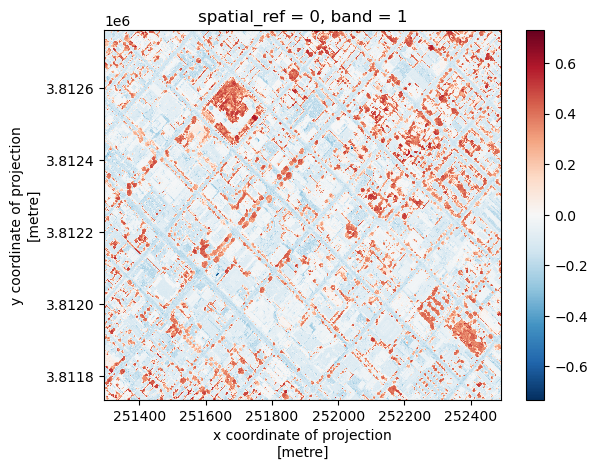

In [42]:
# Calculate the NDVI 
ndvi = (nir16-red16)/(nir16+red16)

ndvi.plot()

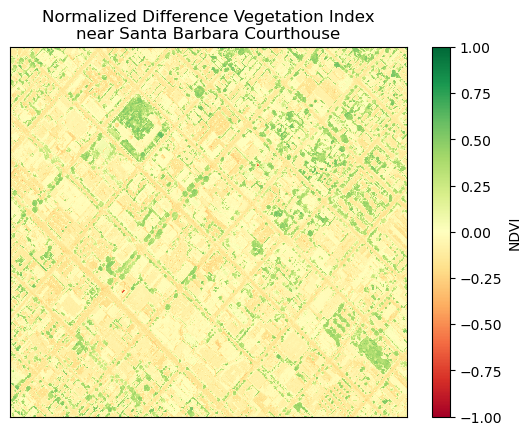

In [43]:
# Plot
fig, ax = plt.subplots()  # Create figure and axes
ndvi.plot(
    ax=ax,
    cmap="RdYlGn",  # Colormap for NDVI
    vmin=-1,  # Minimum value
    vmax=1,   # Maximum value
    cbar_kwargs={"label": "NDVI"}  # Label for color bar
)
ax.set_title("Normalized Difference Vegetation Index\nnear Santa Barbara Courthouse")  # Add title

# Remove axes ticks
ax.set_xticks([])  
ax.set_yticks([])  

# Remove axes labels
ax.set_xlabel("")  
ax.set_ylabel("")  

plt.show()